# Advection equation: dissipation and dispersion

We wish to solve the linear advection equation:

$$\frac{\partial u}{\partial t} + c\,\frac{\partial u}{\partial x} = 0$$

for the same initial profile using 5 schemes: first-order upwind, Lax, leap frog, Lax-Wendroff and MacCormack.

### Notation

$$x \to i\,, \qquad t \to n,$$

so the value at the $i$-th point and the $n$-th time level is $u_i^{\,n}$,
stored as `u[i, n]`, as in the previous notebooks. The Courant number is

$$C = \frac{c\,\Delta t}{\Delta x}.$$

### Summary of schemes:

$$
\begin{aligned}
\text{Upwind:} \quad & u_i^{\,n+1} = u_i^{\,n} - C\left(u_i^{\,n} - u_{i-1}^{\,n}\right)\\[4pt]
\text{Lax-Friedrichs:} \quad & u_i^{\,n+1} = \tfrac{1}{2}\left(u_{i+1}^{\,n} + u_{i-1}^{\,n}\right)
 - \tfrac{C}{2}\left(u_{i+1}^{\,n} - u_{i-1}^{\,n}\right)\\[4pt]
\text{Lax-Wendroff:} \quad & u_i^{\,n+1} = u_i^{\,n}
 - \tfrac{C}{2}\left(u_{i+1}^{\,n} - u_{i-1}^{\,n}\right)
 + \tfrac{C^2}{2}\left(u_{i+1}^{\,n} - 2u_i^{\,n} + u_{i-1}^{\,n}\right)\\[4pt]
\text{Leap frog:} \quad & u_i^{\,n+1} = u_i^{\,n-1}
 - C\left(u_{i+1}^{\,n} - u_{i-1}^{\,n}\right)\\[4pt]
\text{MacCormack:} \quad & \bar{u}_i = u_i^{\,n} - C\left(u_{i+1}^{\,n} - u_i^{\,n}\right),
\qquad u_i^{\,n+1} = \tfrac{1}{2}\left[u_i^{\,n} + \bar{u}_i
 - C\left(\bar{u}_i - \bar{u}_{i-1}\right)\right]
\end{aligned}
$$

## Set-up: grid, ICs/BCs, and the time levels to plot

In [42]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

### 1. Domain Definition (grid creation):

In [43]:
# Advection speed
c = 1.0

# Steps
dx = 0.01   # Step size -> delta_x
dt = 0.008  # Time step -> delta_t

# The Courant number
C_factor = c*dt/dx # should be <= 1 for all four schemes
print("The CFL number is:  ", np.array(C_factor).round(5))

The CFL number is:   0.8


In [44]:
# Limit for the spatial vector
a = 2.0

# Limit for the time vector
b = 0.5

# Axes
x = np.arange(0., a + dx, dx)
t = np.arange(0., b + dt, dt).round(5)

# Number of points on each axis
ni = len(x)
nt = len(t)

#print(ni, nt)

### 2. Set up ICs/BCs:

We use the same square wave as in nb07: 

$u = 2$ between $x = 0.5$ and $x = 1$, and $u = 1$ elsewhere. 

We use this profile because the jump contains every wavenumber the mesh can carry and the schemes differ most at the short ones.

In [45]:
def square_wave(x_vec, x_left = 0.5, x_right = 1.0, u_low = 1.0, u_high = 2.0):
    u_vec = u_low*np.ones_like(x_vec)
    u_vec[(x_vec >= x_left) & (x_vec <= x_right)] = u_high
    return u_vec

In [46]:
# Initial conditions
ics = square_wave(x)

# Boundary Conditions
bcs = [1., 1.] # u = 1 at x=0 and x=a, the far-field value

# Columns of u to draw
n_show = [0, 12, 25, 38, nt - 1]

print(t[n_show])

[0.    0.096 0.2   0.304 0.504]


# Part I. The schemes

Each scheme is one function that takes a solution matrix and fills it in. The
time loop is written out; the spatial loop is replaced by indexing, as in
nb07, because every interior point is treated the same way.

### 1. Matrix builder:

All five schemes start from the same matrix, with the ICs and BCs already in place.

In [47]:
def new_matrix(ics_vec, bcs_pair, n_levels):
    u_mat = np.zeros((len(ics_vec), n_levels))

    u_mat[:,  0] = ics_vec
    u_mat[0,  :] = bcs_pair[0]
    u_mat[-1, :] = bcs_pair[1]

    return u_mat

### 2. Upwind (FTBS):

$$u_i^{\,n+1} = u_i^{\,n} - C\left(u_i^{\,n} - u_{i-1}^{\,n}\right)$$

In [48]:
def march_upwind(ics_vec, bcs_pair, C_num, n_levels):
    u_mat = new_matrix(ics_vec, bcs_pair, n_levels)

    # time loop (index n)
    for n in range(1, n_levels):
        u_old = u_mat[:, n-1]
        u_mat[1:-1, n] = u_old[1:-1] - C_num*(u_old[1:-1] - u_old[:-2])

    return u_mat

### 3. Lax (Lax-Friedrichs):

$$u_i^{\,n+1} = \tfrac{1}{2}\left(u_{i+1}^{\,n} + u_{i-1}^{\,n}\right)
- \tfrac{C}{2}\left(u_{i+1}^{\,n} - u_{i-1}^{\,n}\right)$$

In [49]:
def march_lax(ics_vec, bcs_pair, C_num, n_levels):
    u_mat = new_matrix(ics_vec, bcs_pair, n_levels)

    for n in range(1, n_levels):
        u_old = u_mat[:, n-1]
        u_mat[1:-1, n] = (0.5*(u_old[2:] + u_old[:-2])
                          - 0.5*C_num*(u_old[2:] - u_old[:-2]))

    return u_mat

### 4. Lax-Wendroff:

$$u_i^{\,n+1} = u_i^{\,n}
- \tfrac{C}{2}\left(u_{i+1}^{\,n} - u_{i-1}^{\,n}\right)
+ \tfrac{C^2}{2}\left(u_{i+1}^{\,n} - 2u_i^{\,n} + u_{i-1}^{\,n}\right)$$

In [50]:
def march_lax_wendroff(ics_vec, bcs_pair, C_num, n_levels):
    u_mat = new_matrix(ics_vec, bcs_pair, n_levels)

    for n in range(1, n_levels):
        u_old = u_mat[:, n-1]
        u_mat[1:-1, n] = (u_old[1:-1]
                          - 0.5*C_num*(u_old[2:] - u_old[:-2])
                          + 0.5*C_num**2*(u_old[2:] - 2*u_old[1:-1] + u_old[:-2]))

    return u_mat

### 5. MacCormack:

$$\bar{u}_i = u_i^{\,n} - C\left(u_{i+1}^{\,n} - u_i^{\,n}\right),
\qquad
u_i^{\,n+1} = \tfrac{1}{2}\left[u_i^{\,n} + \bar{u}_i
- C\left(\bar{u}_i - \bar{u}_{i-1}\right)\right]$$

In [51]:
def march_maccormack(ics_vec, bcs_pair, C_num, n_levels):
    u_mat = new_matrix(ics_vec, bcs_pair, n_levels)

    for n in range(1, n_levels):
        u_old = u_mat[:, n-1]

        # predictor: forward difference in space
        u_bar = u_old.copy()
        u_bar[1:-1] = u_old[1:-1] - C_num*(u_old[2:] - u_old[1:-1])

        # corrector: backward difference in space
        u_mat[1:-1, n] = 0.5*(u_old[1:-1] + u_bar[1:-1] - C_num*(u_bar[1:-1] - u_bar[:-2]))

    return u_mat

### 6. Leap frog:

$$u_i^{\,n+1} = u_i^{\,n-1} - C\left(u_{i+1}^{\,n} - u_{i-1}^{\,n}\right)$$

Note that there are 3 time levels, so the march needs a 2nd level before it can start.

One Lax-Wendroff step supplies it. Note that the scheme never mixes the two parities of $n$, so it carries two independent solutions.

In [52]:
def march_leapfrog(ics_vec, bcs_pair, C_num, n_levels):
    u_mat = new_matrix(ics_vec, bcs_pair, n_levels)

    # starter: one Lax-Wendroff step
    u_start = march_lax_wendroff(ics_vec, bcs_pair, C_num, 2)
    u_mat[:, 1] = u_start[:, 1]

    for n in range(2, n_levels):
        u_old = u_mat[:, n-2]   # level n-1 in the formula
        u_now = u_mat[:, n-1]   # level n
        u_mat[1:-1, n] = u_old[1:-1] - C_num*(u_now[2:] - u_now[:-2])

    return u_mat

### 7. Running the five schemes on the same grid:

In [54]:
# Numerical integration step
u_up = march_upwind(ics, bcs, C_factor, nt)
u_lx = march_lax(ics, bcs, C_factor, nt)
u_lf = march_leapfrog(ics, bcs, C_factor, nt)
u_lw = march_lax_wendroff(ics, bcs, C_factor, nt)
u_mc = march_maccormack(ics, bcs, C_factor, nt)

# List of schemes for plotting
schemes = [("Upwind", u_up), ("Lax", u_lx), ("Leap frog", u_lf), ("Lax-Wendroff", u_lw), ("MacCormack", u_mc)]

# MacCormack duplicates Lax-Wendroff here, so the plots use the first four
plot_set = schemes[:4]

### 8. Note: MacCormack versus Lax-Wendroff:

Please note that for the linear advection equation the predictor-corrector pair collapses algebraically onto Lax-Wendroff. 

If the two matrices do not agree to machine precision, one of the two functions above is wrong.

In [55]:
print("The largest difference is :", np.abs(u_lw - u_mc).max())

The largest difference is : 2.220446049250313e-15


# Part II. Plotting solutions

In [56]:
# Exact solution

u_exact = square_wave(x - c*t[-1])

#### A. Profiles at the final time:

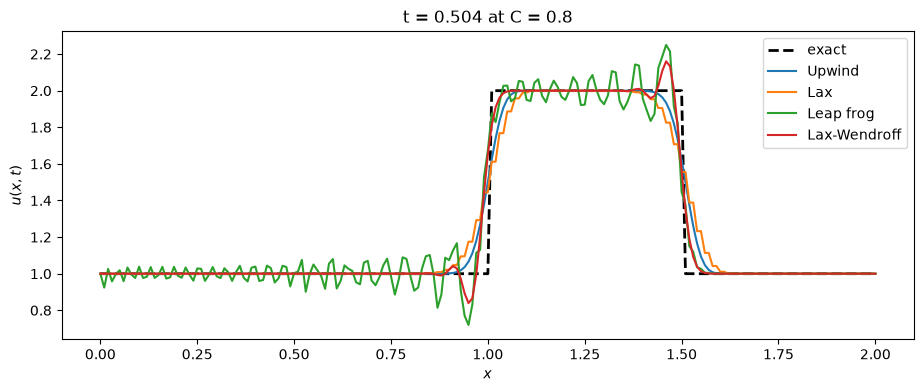

In [57]:
plt.figure(figsize=(11,4))

plt.plot(x, u_exact, "k--", lw = 2, label = "exact")

for name, u_mat in plot_set:
    plt.plot(x, u_mat[:, -1], label = name)

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.title(f"t = {t[-1]} at C = {C_factor}")

plt.legend()

plt.show()

#### B. Close-up of the leading edge:

The upstream side of the rising step is where the dispersive error shows.

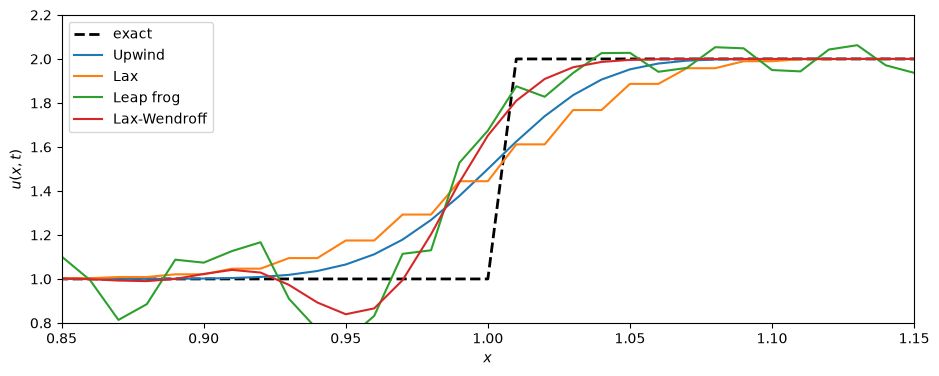

In [58]:
plt.figure(figsize=(11,4))

plt.plot(x, u_exact, "k--", lw = 2, label = "exact")

for name, u_mat in plot_set:
    plt.plot(x, u_mat[:, -1], label = name)

plt.xlim(0.85, 1.15)
plt.ylim(0.80, 2.20)

plt.xlabel(r"$x$")
plt.ylabel(r"$u(x,t)$")

plt.legend()

plt.show()

#### C. Time evolution of each profile:

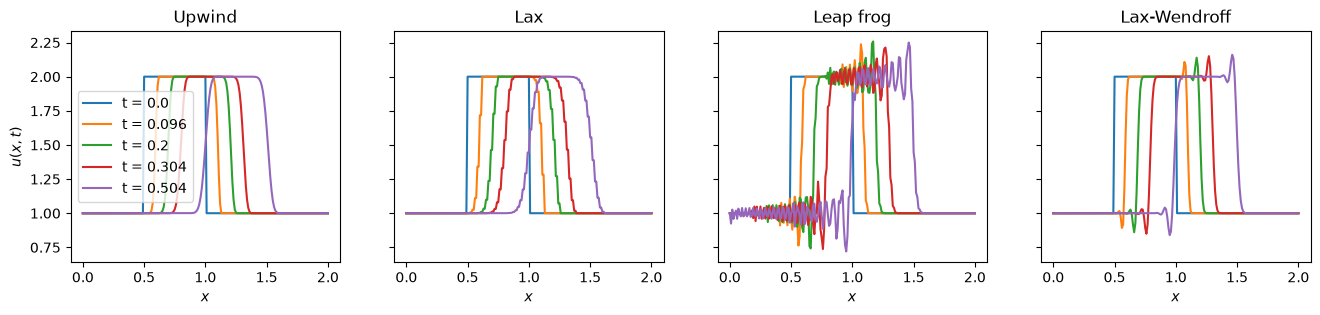

In [59]:
fig, ax = plt.subplots(1, 4, figsize = (16,3), sharey = True)

for a_i, (name, u_mat) in zip(ax, plot_set):
    for n in n_show:
        a_i.plot(x, u_mat[:, n], label = f"t = {t[n]}")
    a_i.set_title(name)
    a_i.set_xlabel(r"$x$")

ax[0].set_ylabel(r"$u(x,t)$")
ax[0].legend()

plt.show()

# Part III. The amplification factor and the phase

The modified equations predict the two errors mode by mode. For each scheme the amplification factor is

$$
\begin{aligned}
G_{\rm up} &= 1 - C\left(1 - e^{-\mathrm{i}\theta}\right), \\
G_{\rm LF} &= \cos\theta - \mathrm{i}\,C\sin\theta, \\
G_{\rm LW} &= 1 - C^2\left(1 - \cos\theta\right) - \mathrm{i}\,C\sin\theta,
\end{aligned}
\qquad \theta = k\,\Delta x .
$$

$|G|$ is the amplitude left after one step.

The numerical speed follows from the argument of $G$: a mode that travels at $c$ exactly turns by $C\theta$ per step, so the ratio $\arg(G^{-1})/(C\theta)$ is the speed in units of $c$.

In [60]:
# Theta vector:
theta = np.linspace(1e-6, np.pi, 400)

In [61]:
def G_factors(C_num, theta_vec):
    return {
        "upwind": 1. - C_num*(1. - np.exp(-1j*theta_vec)),
        "Lax": np.cos(theta_vec) - 1j*C_num*np.sin(theta_vec),
        "leap frog": (np.sqrt(1. - C_num**2*np.sin(theta_vec)**2)
                      - 1j*C_num*np.sin(theta_vec)),
        "Lax-Wendroff": (1. - C_num**2*(1. - np.cos(theta_vec))
                         - 1j*C_num*np.sin(theta_vec)),
    }

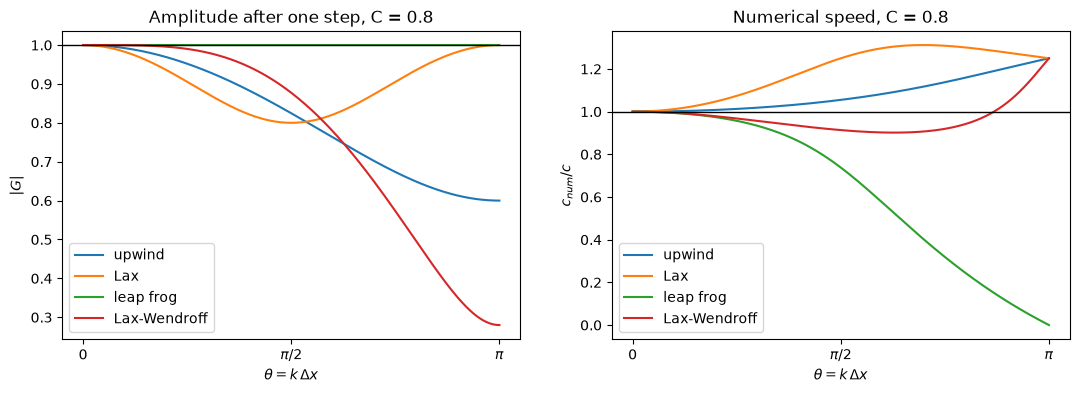

In [62]:
fig, ax = plt.subplots(1, 2, figsize = (13,4))

G_all = G_factors(C_factor, theta)

for name, G in G_all.items():
    ax[0].plot(theta, np.abs(G), label = name)
    ax[1].plot(theta, np.unwrap(-np.angle(G))/(C_factor*theta), label = name)

ax[0].axhline(1.0, color = "k", lw = 1.0)
ax[1].axhline(1.0, color = "k", lw = 1.0)

ax[0].set_ylabel(r"$|G|$")
ax[1].set_ylabel(r"$c_{num}/c$")

for a_i in ax:
    a_i.set_xlabel(r"$\theta = k \, \Delta x$")
    a_i.set_xticks([0, np.pi/2, np.pi])
    a_i.set_xticklabels(["0", r"$\pi/2$", r"$\pi$"])
    a_i.legend()

ax[0].set_title(f"Amplitude after one step, C = {C_factor}")
ax[1].set_title(f"Numerical speed, C = {C_factor}")

plt.show()

### Summary of results

Dissipation changes the **amplitude** of each mode and leaves its speed; dispersion changes the **speed** and leaves its amplitude.

#### Dissipative schemes: upwind and Lax

- Both lead with the even-order term $\nu_2 u_{xx}$, with $\nu_2 > 0$, so each mode is damped by $\exp(-\nu_2 k^2 t)$, and the short ones go first.

- Every mode still travels at $c$, so nothing is displaced and the profile stays monotone. No overshoots and undershoots are present.

- Lax is the more diffusive of the two, $\tfrac{1}{2}c\,\Delta x\,(1 - C^2)/C$ against $\tfrac{1}{2}c\,\Delta x\,(1 - C)$ for upwind.

- That gap widens as $C$ falls, so reducing $\Delta t$ at fixed mesh makes Lax worse.

#### Dispersive schemes: leap frog and Lax-Wendroff

- Both lead with the odd-order term $-\tfrac{1}{6}c\,\Delta x^2(1 - C^2)u_{xxx}$.

- Each mode travels at $c + \nu_3 k^2 < c$, and the short ones lag furthest behind.

- No mode is damped, so the short waves survive to build a steep edge

- Leap frog has $|G| = 1$ at every wavenumber, so its oscillations are never damped.

- Lax-Wendroff has a weak fourth-order dissipation, so its oscillations decay slowly.